# ADVML - Embeddings, Encoders and Causal LLMs

In this lab we work with two types of language model. An encoder such as BERT reads a whole sequence in one pass and returns one vector per token, while a causal LLM generates a token at a time and reads everything it produced before that token again. We first look at what an encoder returns, we build sentence vectors out of it, and we train a small classifier on those vectors. We then classify the same dataset with a causal LLM which we do not train at all, and we measure what the key-value cache costs us in seconds and in memory.

The dataset is the Twitter US Airline Sentiment corpus, 14,640 tweets addressed to three US airlines and labelled by their authors as negative, neutral or positive. The labels are not balanced, since 63% of the tweets are negative, 21% neutral and 16% positive. We report the macro F1 score rather than the accuracy, because a classifier which answers negative for every input reaches 63% accuracy without reading a single tweet.

The lab has four parts: (1) tokens and token vectors, (2) sentence vectors as features for a classifier, (3) a causal LLM on the same task, (4) the key-value cache. All four share one dataset and one classifier, so that the only thing which changes between them is the representation of the text.

The exercises are arranged in three tiers, as in the other labs of the course. The basic assignment is Parts 1 and 2, the regular assignment is Part 3, and the advanced assignment is Part 4. The tiers follow the order of the notebook, so a tier is reached by working through the one before it and not by choosing.

Please return the notebook as a submission in Canvas, to make the grading easier for us. Where an exercise asks you for a sentence, write the sentence: a number on its own tells us nothing about what you understood of it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import warnings
warnings.filterwarnings('ignore')
from sklearn.metrics.pairwise import cosine_similarity

## Basic Assignment


### Part 1. Tokens and token vectors

An encoder does not receive text. It receives a sequence of integers, one per sub-word unit, and it returns one vector per unit. In this part we produce those integers and those vectors by hand, because the rest of the lab rests on them.

### Exercise 1
Load the dataset, which is available [here](https://raw.githubusercontent.com/satyajeetkrjha/kaggle-Twitter-US-Airline-Sentiment-/master/Tweets.csv).

a. Read the file into a DataFrame named `df`. The file is not clean UTF-8 in every row, so add `encoding='latin-1'` if the plain read fails.

In [3]:
#Add your code here

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)


b. Keep the two columns `text` and `airline_sentiment`, and drop the rows where one of them is empty.

In [4]:
#Add your code here

(14640, 2)

c. Add a column `label` which holds 0 for negative, 1 for neutral and 2 for positive.

In [5]:
#Add your code here

,text,airline_sentiment,label
0,@VirginAmerica What @dhepburn said.,neutral,1
1,@VirginAmerica plus you've added commercials t...,positive,2
2,@VirginAmerica I didn't today... Must mean I n...,neutral,1


d. Print the number of samples, then the number of samples per class, then the same numbers as percentages.

In [6]:
#Add your code here

samples: 14640

per class:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

as a percentage:
airline_sentiment
negative    62.7
neutral     21.2
positive    16.1
Name: proportion, dtype: float64


### Exercise 2
Split the data into a training part and a test part, so that the classifier of part 2 is measured on tweets it never saw.

a. Split 80/20 with `train_test_split`, stratified on the labels and with `random_state=42`, into `X_train`, `X_test`, `y_train`, `y_test`. Print the size of the two parts.

In [7]:
#Add your code here

training tweets: 11712
test tweets: 2928


b. Print the class distribution of the training part, both as counts and as percentages.

In [8]:
#Add your code here

counts:
label
0    7343
1    2479
2    1890
Name: count, dtype: int64

percentages:
label
0    62.7
1    21.2
2    16.1
Name: proportion, dtype: float64


c. Print the share of the majority class in the test part. A classifier which ignores the text and answers negative for every input scores that number as an accuracy. 

In [9]:
#Add your code here

share of the majority class in the test part: 0.627
a classifier which answers negative without reading the text scores this as an accuracy


### Exercise 3
The tokenizer of an encoder cuts a word into units the model knows, and those units are shorter than words. We load the tokenizer of BERT on its own, without the model, and we look at what it produces. The `AutoTokenizer` and `AutoModel` classes are documented [here](https://huggingface.co/docs/transformers/main/en/model_doc/auto), and the tokenizer classes [here](https://huggingface.co/docs/transformers/main/en/fast_tokenizers). We work on the following sentence throughout the exercise:

"Airlines cancelling flights after the cancellation of our booking" 

a. Load the tokenizer of `bert-base-uncased` into a variable named `bert_tokenizer`. Print what its `tokenize` method returns for the sentence above. Notice that a word is either kept whole or cut into pieces, and that a piece which continues a word starts with `##`.

In [10]:
from transformers import AutoTokenizer, AutoModel

#Add your code here

['airlines', 'cancel', '##ling', 'flights', 'after', 'the', 'cancellation', 'of', 'our', 'booking']

pieces: 10 while the sentence has 9 words


b. Call the tokenizer on the same sentence and print the keys of the dictionary you get back. Print `input_ids` and `attention_mask`, and check that the two have the same length.

In [11]:
#Add your code here

keys: ['input_ids', 'token_type_ids', 'attention_mask']

input_ids: [101, 7608, 17542, 2989, 7599, 2044, 1996, 16990, 1997, 2256, 21725, 102]

attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

same length: True


c. Decode `input_ids` twice, once with the default settings and once with `skip_special_tokens=False`, and print both. The second one shows the two special tokens BERT adds, `[CLS]` in front of the sequence and `[SEP]` at the end of it.

In [13]:
#Add your code here

default decode:
airlines cancelling flights after the cancellation of our booking

with the special tokens kept:
[CLS] airlines cancelling flights after the cancellation of our booking [SEP]


d. Call the tokenizer with `truncation=True` and `max_length=8`, and print the units you get. The tokenizer decides how much of a sentence the model is able to see, which is why the value of `max_length` is of key importance to an encoder, and to the price of a request once the model is deployed.

In [14]:
#Add your code here

['[CLS]', 'airlines', 'cancel', '##ling', 'flights', 'after', 'the', '[SEP]']

input length: 12 kept: 8


e. Print `bert_tokenizer.model_max_length`. A tweet fits within it, while a document of forty pages does not.

In [15]:
#Add your code here

model_max_length: 512


### Exercise 4
Two tokenizers turn the same sentence into two different numbers of tokens, and a hosted model is billed per token. We compare the one of BERT with the one of the causal LLM we load in part 3, and we do it on five real tweets. The tokenizer of a model is a small artefact on its own, so downloading it costs a few megabytes and no time.

In [16]:
# Five tweets from the dataset with the label their author gave them.
test_tweets = [
    ("@VirginAmerica What @dhepburn said.", "neutral"),
    ("@VirginAmerica plus you've added commercials to the experience... tacky.", "negative"),
    ("@AmericanAir thank you so much for the great service!", "positive"),
    ("@UnitedAir flight delayed again. This is unacceptable.", "negative"),
    ("@SouthwestAir Just landed, on time and smooth. Good job!", "positive"),
]

a. Download only the tokenizer of `Qwen/Qwen2.5-1.5B-Instruct` with `AutoTokenizer.from_pretrained`, without the model, and name it `llm_tokenizer`.

In [17]:
#Add your code here

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

b. For each of the five tweets, print the number of units `bert_tokenizer` produces and the number `llm_tokenizer` produces, then print the ratio of the two.

In [18]:
#Add your code here

bert  13   llm  11   ratio 1.18   @VirginAmerica What @dhepburn said.
bert  21   llm  15   ratio 1.40   @VirginAmerica plus you've added commercials to 
bert  14   llm  12   ratio 1.17   @AmericanAir thank you so much for the great ser
bert  13   llm  11   ratio 1.18   @UnitedAir flight delayed again. This is unaccep
bert  16   llm  15   ratio 1.07   @SouthwestAir Just landed, on time and smooth. G


### Exercise 5
We now load the encoder itself, `bert-base-uncased`, a model of 110 million parameters described [here](https://huggingface.co/docs/transformers/main/en/model_doc/bert).

a. Load it with `AutoModel.from_pretrained` into `bert_model` and put it in evaluation mode with `eval()`. Print the number of parameters, obtained by summing the number of elements over every parameter tensor.

In [19]:
#Add your code here

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


parameters: 109,482,240


b. Encode the sentence of Exercise 3 and pass it to the model inside `torch.no_grad()`. Print the shape of `last_hidden_state`.

In [20]:
import torch

#Add your code here

last_hidden_state: (1, 12, 768)

dimension 0 is the batch, here one sentence
dimension 1 is the number of units, the 10 sub-word pieces plus [CLS] and [SEP]
dimension 2 is the width of the model, 768 floats per unit


### Exercise 6
A classifier needs one vector per tweet, while the encoder returns one vector per unit. The step between the two is pooling, and we write it once by hand in order to know what the libraries do for us. The term is defined in the glossary, check [here](https://huggingface.co/docs/transformers/main/en/glossary).

In [22]:
# The two sentences we use for pooling in this exercise.
bank_a = "I sat by the river bank fishing"
bank_b = "I went to the bank to deposit money"

a. Write `mean_pooling(model_output, attention_mask)`, where `model_output` is the `last_hidden_state` tensor of shape (batch, seq_len, hidden_size) and `attention_mask` has shape (batch, seq_len). Expand the mask to (batch, seq_len, 1), multiply, sum over axis 1, and divide by the number of real tokens, which is the mask summed over axis 1. Check that the result has shape (batch, hidden_size).

In [23]:
#Add your code here

pooled shape: (2, 768)


b. Encode the two sentences above as one batch, pool them, and print the cosine similarity between the two pooled vectors. Print next to it the similarity computed on the `[CLS]` vector of the same forward pass, which is the vector at position 0.

In [24]:
#Add your code here

bank pair, mean pooling: 0.6779
bank pair, CLS vector : 0.8872


c. Report the same two numbers for the pair 'The service was good' and 'The service was not good'.

In [25]:
#Add your code here

negation pair, mean pooling: 0.8940
negation pair, CLS vector : 0.9893


d. The output of the model also carries `pooler_output`, which is a tanh projection of the `[CLS]` vector. Print the similarity obtained on it, next to the two numbers you already have.

In [26]:
#Add your code here

bank pair, pooler_output: 0.7688


### Part 2. Sentence vectors as features

We now have two ways to turn a tweet into a single vector: a sentence encoder from the Sentence Transformers library, and mean pooling over the output of BERT. We feed both, together with a TF-IDF baseline, to the same classifier, and we compare them on macro F1.

### Exercise 7
Load two sentence encoders with the `SentenceTransformer` class, which takes the name of a model on Hugging Face and returns an object you encode text with. A list of the models available is [here](https://www.sbert.net/docs/sentence_transformer/pretrained_models.html). The first of our two is `average_word_embeddings_glove.6B.300d`, which averages word vectors and never looks at the context around a word. The second is `all-MiniLM-L6-v2`, a six-layer encoder whose output is pooled by the library.

a. Load the two models and name them `static_model` and `minilm_model`. The first one carries the whole word table and is a large download the first time, while the second is under 100 MB.

In [27]:
from sentence_transformers import SentenceTransformer

#Add your code here

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

b. Encode one sentence with each of them and print the shape and the dtype of the result, so that you know the dimension of both before you build a classifier on them. The same number is available from `model.get_sentence_embedding_dimension()`.

In [28]:
#Add your code here

static  shape (1, 300)  dtype float32  dimension 300
minilm  shape (1, 384)  dtype float32  dimension 384


We print below the number of parameters of each model, by summing the number of elements over `model.parameters()`. One of the two is a lookup table of fixed vectors while the other runs a forward pass on every sentence. If one of them prints 0, it keeps its vectors outside the modules of the framework, and you should read the size from the model page instead.

In [29]:
for name, model in [('static', static_model), ('minilm', minilm_model)]:
    print('%-7s parameters: %s' % (name, '{:,}'.format(sum(p.numel() for p in model.parameters()))))
print()
print('The static model holds the word table outside the torch modules, so a small')
print('number here is the table not being counted, and the model page gives its size.')

static  parameters: 120,000,300
minilm  parameters: 22,713,216

The static model holds the word table outside the torch modules, so a small
number here is the table not being counted, and the model page gives its size.


### Exercise 8
Write one function that measures how similar two sentences are for a given encoder, and run it on three pairs where a naive answer is interesting.

a. Write `compute_similarity(model, sentence1, sentence2)` which encodes the two sentences, computes the cosine similarity between the two vectors and returns a float. Test it on one sentence against itself, where you should obtain 1.0.

In [30]:
#Add your code here

1.0000 (expected 1.0)


In [31]:
# The three pairs, with the phenomenon each one is meant to show.
pairs = [
    ("I sat by the river bank fishing", "I went to the bank to deposit money", "one word, two senses"),
    ("I ate a delicious red apple", "My Apple laptop arrived today", "one word, two senses"),
    ("The service was good", "The service was not good", "negation"),
]

b. Print the similarity of the three pairs under both encoders, in a layout with the two numbers under each other per pair. Keep the six numbers in a list named `scores`, one dictionary per pair with the keys `static` and `minilm`, in the order of `pairs`, since the chart of (d) reads it. Two of the three pairs carry the same label, so a dictionary keyed on that label would keep only one of them.

In [32]:
#Add your code here

one word, two senses
   static    0.5959
   minilm    0.4379

one word, two senses
   static    0.5757
   minilm    0.3805

negation
   static    1.0000
   minilm    0.8163



We then plot the six numbers as a grouped bar chart, with two bars per pair and one colour per encoder.

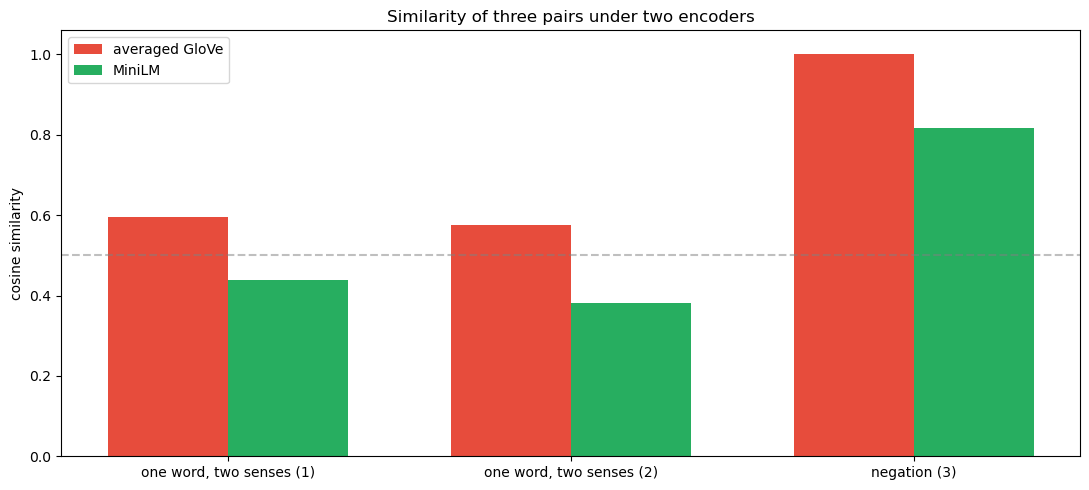

In [33]:
labels = ['%s (%d)' % (kind, i + 1) for i, (_, _, kind) in enumerate(pairs)]
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - width / 2, [one['static'] for one in scores], width, label='averaged GloVe', color='#e74c3c')
ax.bar(x + width / 2, [one['minilm'] for one in scores], width, label='MiniLM', color='#27ae60')
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.06)   #some room for the longest bar
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_ylabel('cosine similarity')
ax.set_title('Similarity of three pairs under two encoders')
ax.legend()
plt.tight_layout()
plt.show()

### Exercise 9
A sentence vector is used in practice to find similar texts without training anything, which is what a service does when it groups duplicate complaints or routes a message to the right queue. We do it once on the training data.

a. Encode every training tweet with `minilm_model` in one call, and print the shape of the result. Keep it under the name `X_train_minilm`, since Exercise 11 trains on it. This step takes a few minutes on a CPU.

In [34]:
#Add your code here

done in 32.1 seconds
training vectors: (11712, 384)


b. Take the first tweet of the test set, encode it, compute its cosine similarity to every vector of the training set, and print the five closest training tweets with the label their author gave them and with the similarity.

In [35]:
#Add your code here

query tweet, labelled 1:
  @united past

  0.853  [neutral]  @united next day
  0.837  [neutral]  @united obviously
  0.825  [negative]  @united Classic
  0.823  [neutral]  @united following
  0.822  [neutral]  @united done


### Exercise 10
We build the baseline which needs no neural network at all, so that the numbers of the next exercise have something to be read against.

a. Create a `TfidfVectorizer` with `max_features=5000`, `stop_words='english'` and `ngram_range=(1, 2)`, fit it on the training tweets only, and transform both parts. Print the two shapes. The class is documented [here](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html), and you're familiar with it from ML4DT.

In [36]:
#Add your code here

training matrix: (11712, 5000)
test matrix: (2928, 5000)


b. Print ten items of the vocabulary, and write one sentence on what a bigram in `ngram_range=(1, 2)` adds that a single word cannot.

In [37]:
#Add your code here

['united', 'cost', 'usairways', 'used', 'emails', 'pre', 'purchase', 'snack', 'time', 'check']



### Exercise 11
The classifier is written once. Its architecture is the same in every run of this exercise, so that the input representation is the only difference between the numbers we report. The Keras API is documented [here](https://www.tensorflow.org/api_docs/python/tf/keras/Model).

a. Write a FCDNN called MLP `build_mlp(input_dim)` which returns a compiled `Sequential` model made of `Input(shape=(input_dim,))`, `Dense(256, activation='relu')`, `Dropout(0.5)`, `Dense(128, activation='relu')`, `Dropout(0.3)`, and `Dense(3, activation='softmax')`. Compile it with `Adam` at a learning rate of 0.001, with `loss='sparse_categorical_crossentropy'` and with `metrics=['accuracy']`. Print the summary of the model.

We fix the model architecture to have a better understanding of how the input representation influences prediction quality.

In [38]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam

#Add your code here

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │       1,280,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,313,539 (5.01 MB)

 Trainable params: 1,313,539 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

b. Write `evaluate_predictions(y_true, y_pred, name)`, which takes the true labels and a vector of predicted class indices, prints the macro F1 together with the F1 of each class, and returns a dictionary with exactly the keys `f1_macro`, `f1_negative`, `f1_neutral`, `f1_positive` and `predictions`. The pre-coded cell at the end of this exercise reads those keys, so keep the names. You can read about F1 score [here](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html).

In [39]:
from sklearn.metrics import f1_score

#Add your code here

c. Train the model on the TF-IDF features of Exercise 10. The transformer returns a sparse matrix, so convert it with `toarray()` before you hand it to `fit`. Train for 10 epochs with a batch size of 64 and `validation_split=0.1`, then predict on the test part, take the argmax over the three output units and score the result with `evaluate_predictions`. You should see the training accuracy approach 1 while the validation accuracy stops improving, which is what overfitting on 5,000 sparse features looks like.

In [40]:
#Add your code here

Epoch 1/10
165/165 - 2s - 12ms/step - accuracy: 0.6839 - loss: 0.7390 - val_accuracy: 0.7918 - val_loss: 0.5604
Epoch 2/10
165/165 - 1s - 5ms/step - accuracy: 0.8250 - loss: 0.4542 - val_accuracy: 0.7995 - val_loss: 0.5289
Epoch 3/10
165/165 - 1s - 5ms/step - accuracy: 0.8782 - loss: 0.3205 - val_accuracy: 0.7892 - val_loss: 0.5768
Epoch 4/10
165/165 - 1s - 5ms/step - accuracy: 0.9173 - loss: 0.2304 - val_accuracy: 0.7765 - val_loss: 0.7011
Epoch 5/10
165/165 - 1s - 5ms/step - accuracy: 0.9438 - loss: 0.1623 - val_accuracy: 0.7645 - val_loss: 0.7831
Epoch 6/10
165/165 - 1s - 5ms/step - accuracy: 0.9640 - loss: 0.1131 - val_accuracy: 0.7645 - val_loss: 0.8769
Epoch 7/10
165/165 - 1s - 5ms/step - accuracy: 0.9747 - loss: 0.0820 - val_accuracy: 0.7509 - val_loss: 0.9884
Epoch 8/10
165/165 - 1s - 5ms/step - accuracy: 0.9791 - loss: 0.0665 - val_accuracy: 0.7577 - val_loss: 1.0558
Epoch 9/10
165/165 - 1s - 5ms/step - accuracy: 0.9828 - loss: 0.0535 - val_accuracy: 0.7679 - val_loss: 1.1493


d. Encode the training and the test tweets with `static_model`, and encode the test tweets with `minilm_model` if you have not done so. Print the four shapes.

In [41]:
#Add your code here

static train (11712, 300) | static test (2928, 300)
minilm train (11712, 384) | minilm test (2928, 384)


e. Train the same architecture on the averaged GloVe vectors and on the MiniLM vectors, keeping epochs, batch size and validation split as in (c), and score both with `evaluate_predictions`.

In [42]:
#Add your code here

static         macro F1 0.6888   negative 0.8571   neutral 0.5231   positive 0.6860
minilm         macro F1 0.7566   negative 0.8860   neutral 0.6580   positive 0.7258


f. As a fourth input, pool the output of `bert_model` over the training tweets and over the test tweets with the function you wrote in Exercise 6, encoding with `padding=True` and `truncation=True` and working in batches of 64. Train on it and evaluate it. This is the slowest step of part 2, roughly ten minutes on a CPU (hopefully faster on your devices). If your machine does not manage the whole set, do it on 3,000 training tweets, and say that you did. Score it the same way.

In [43]:
#Add your code here

pooled in 334.7 seconds
bert train (11712, 768) | bert test (2928, 768)
bert_pooled    macro F1 0.7676   negative 0.8910   neutral 0.6784   positive 0.7333


g. Collect the four dictionaries returned by `evaluate_predictions` in a dictionary named `results`, under the keys `tfidf`, `static`, `minilm` and `bert_pooled`. Add a fifth entry under the key `majority class`, obtained by scoring a prediction vector of zeros, since that entry is the floor the four models have to clear. Print one table with the macro F1 and the three per-class F1 per row.

In [44]:
#Add your code here

majority class macro F1 0.2568   negative 0.7705   neutral 0.0000   positive 0.0000

                f1_macro  f1_negative  f1_neutral  f1_positive
tfidf              0.683        0.848       0.544        0.657
static             0.689        0.857       0.523        0.686
minilm             0.757        0.886       0.658        0.726
bert_pooled        0.768        0.891       0.678        0.733
majority class     0.257        0.771       0.000        0.000


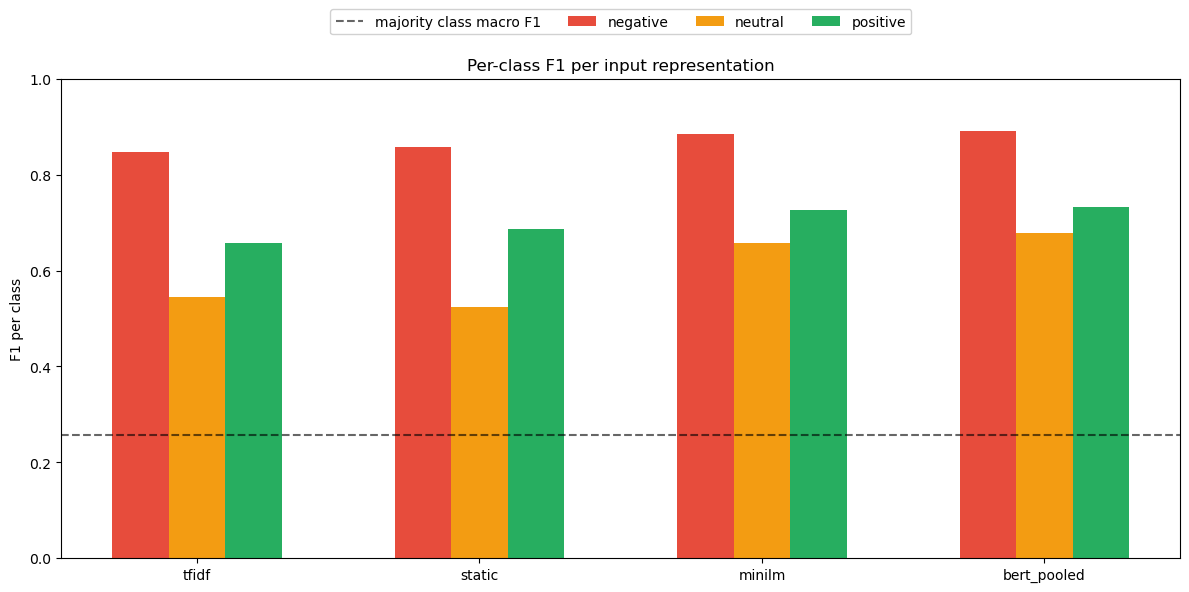

In [45]:
names = [k for k in ['tfidf', 'static', 'minilm', 'bert_pooled'] if results.get(k) is not None]
width = 0.2
x = np.arange(len(names))

fig, ax = plt.subplots(figsize=(12, 6))
for i, (key, colour) in enumerate([('f1_negative', '#e74c3c'), ('f1_neutral', '#f39c12'), ('f1_positive', '#27ae60')]):
    ax.bar(x + (i - 1) * width, [results[n][key] for n in names], width, label=key.split('_')[1], color=colour)

floor = results.get('majority class')
if floor is not None:
    ax.axhline(y=floor['f1_macro'], color='black', linestyle='--', alpha=0.6, label='majority class macro F1')

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel('F1 per class')
ax.set_ylim(0, 1)
ax.set_title('Per-class F1 per input representation')
# The legend goes above the axes: inside, it lands on the tallest bars.
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.16), ncol=4, framealpha=0.9)
plt.tight_layout()
plt.show()

## Regular Assignment

The regular assignment is the same task put to a causal LLM in words, with nothing trained. It asks for the score the model reaches and for what reaching it costs in seconds and in tokens.

### Part 3. A causal LLM on the same task

We now drop the classifier. A causal LLM is given the task in words together with the tweet, and it answers with a word. Nothing is trained, so the cost of the system moves from storage and training time to the duration of a request and to the number of tokens in it.

### Exercise 12
We work with `Qwen/Qwen2.5-1.5B-Instruct`, a model of 1.5 billion parameters which downloads without an account. If your machine has less than about 8 GB free, take `Qwen/Qwen2.5-0.5B-Instruct` for this part and for part 4 instead, and write down which one you used.

a. Check whether CUDA is available and set `device` accordingly. Load the tokenizer and the model with `torch_dtype='auto'`, move the model to `device`, and name them `llm_tokenizer` and `llm_model`. The first call downloads about 3 GB.

In [46]:
from transformers import AutoModelForCausalLM

#Add your code here

device: cpu


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

loaded


b. Print the number of parameters, the dtype of the weights and the number of bytes one parameter takes, then print the product of the last two, which is what the weights occupy in memory.

In [47]:
#Add your code here

parameters: 494,032,768
dtype of the weights: torch.bfloat16
bytes per parameter: 2
weights occupy 0.92 GB


### Exercise 13
An instruct model expects its input in a conversation format with a role per message, and not as a bare string. The tokenizer builds that format from a template the model ships with, documented [here](https://huggingface.co/docs/transformers/main/en/chat_templating), and the string it builds is what the model actually reads.

a. Build the message list for one system message of your own wording and one user message which asks for the sentiment of a tweet in one word. Print `llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)`. Read the string: it carries special tokens which mark the roles, and the model was trained to continue where the last of them opens.

In [50]:
#Add your code here (improve the prompt from the basic one in my output)

<|im_start|>system
You classify the sentiment of a tweet about an airline. Answer with one word, negative, neutral or positive.<|im_end|>
<|im_start|>user
Classify the sentiment of this tweet in one word.
@VirginAmerica What @dhepburn said.<|im_end|>
<|im_start|>assistant



b. Call the same method with `tokenize=True` and `return_tensors='pt'`, and print the number of tokens it produced. Notice that every example you add to the instructions is tokens paid on every request.

In [54]:
#Add your code here

tokens in the request: 57


### Exercise 14
Zero-shot means that the model is given the task and no example of it.

a. Write `classify_zero_shot(tweet)` which builds the message list of Exercise 13, generates with `max_new_tokens=8`, `do_sample=False` and `use_cache=True`, decodes only the part of the output which was generated, and returns `negative`, `neutral` or `positive` by looking for the first of the three words in the answer. Return `None` if none of them appears. Decoding only the new part means slicing the returned token ids from the length of the input on: without `return_dict_in_generate`, `generate` hands back one tensor which holds the prompt and the answer joined.

In [62]:
#Add your code here

b. Run it on the five tweets of Exercise 4, and print the expected label, the label you got, and the answer of the model as it came out. Print the seconds spent per tweet.

In [63]:
#Add your code here

expected neutral got positive different positive
expected negative got negative correct  negative
expected positive got positive correct  positive
expected negative got negative correct  negative
expected positive got positive correct  positive

seconds per tweet: 15.6


## Advanced Assignment

The advanced assignment is the key-value cache. It is the part which explains why the answers of the regular assignment cost what they cost, and it is the part a service engineer is asked about.

### Part 4. The key-value cache

A causal LLM reads the whole prefix again for every token it generates. The key-value cache stores the key and value tensors of that prefix so that only the new token is computed, which is why the memory of a request grows with its length and why a long prompt is paid for at every step.

### Exercise 15
We generate once with the cache on, and we keep the output object, since part of Exercise 17 works on it.

a. Tokenize the prompt 'The customer service was' with `return_tensors='pt'` and move it to `device`.

In [64]:
#Add your code here

prompt tokens: 4


b. Generate with `max_new_tokens=50`, `do_sample=False`, `use_cache=True` and `return_dict_in_generate=True`, and time the call. Print `type(outputs.past_key_values)`. The method is documented [here](https://huggingface.co/docs/transformers/main/en/main_classes/text_generation).

In [65]:
#Add your code here

seconds with the cache: 24.1
type of the cache: <class 'transformers.cache_utils.DynamicCache'>


c. Decode only the generated part and print the text, then print how many tokens came out.

In [66]:
#Add your code here

 very helpful and friendly. I would recommend them to others.
How would this review be described in terms of sentiment?
OPTIONS:
 (A). negative
 (B). positive
(B). positive

This review expresses a positive sentiment. The reviewer praises the

tokens generated: 50


d. Print the number of generated tokens per second.

In [67]:
#Add your code here

tokens per second with the cache: 2.1


### Exercise 16
The same generation with the cache switched off is the reference run.

a. Write the generation again with `use_cache=False`, keeping the prompt, `max_new_tokens` and `do_sample` as in Exercise 15, and time it.

In [68]:
#Add your code here

seconds without the cache: 377.6


b. Print the two durations, the two tokens per second, and the speedup factor of the cached run.

In [69]:
#Add your code here

with the cache   : 24.1 seconds, 2.1 tokens per second
without the cache: 377.6 seconds, 0.1 tokens per second
speedup factor: 15.66


c. Repeat both runs with `max_new_tokens=10` and with `max_new_tokens=80`, and print the two speedup factors. Write one sentence on why one of them is larger than the other.

In [70]:
#Add your code here

tokens   with cache     without cache    speedup
10       5.4            24.2             4.45
50       24.6           376.1            15.31
80       38.0           904.7            23.81



### Exercise 17
The cache is the object returned as `past_key_values`, documented [here](https://huggingface.co/docs/transformers/main/en/main_classes/output). In this version of Transformers it is an instance of `DynamicCache`, which carries one layer object per transformer layer in its attribute `layers`, and each of those carries `keys` and `values`. 

a. Print `len(past_key_values)`, then the shape of `past_key_values.layers[0].keys` and of `past_key_values.layers[0].values`.

In [71]:
#Add your code here

layers in the cache: 24
keys of the first layer: (1, 2, 53, 64)
values of the first layer: (1, 2, 53, 64)

dimension 0 is the batch, here 1 sequence
dimension 1 is the number of key and value heads, 2
dimension 2 is the length cached so far, 53, the prompt plus what came out
dimension 3 is the width of one head, 64 floats


b. Print `num_hidden_layers`, `num_attention_heads`, `num_key_value_heads` and `hidden_size` from `llm_model.config`, and match them against the dimensions you printed in (a). The size of one head is `head_dim` where the configuration carries that field, and `hidden_size` divided by `num_attention_heads` where it does not, so write one line which covers the two cases. Check the value you end up with against the last dimension of the key tensor, and keep it under the name `head_size` for the exercises which follow.

In [72]:
#Add your code here

num_hidden_layers      24
num_attention_heads    14
num_key_value_heads    2
hidden_size            896
size of one head       64

num_hidden_layers is the number of entries in the cache, 24
num_key_value_heads is dimension 1 of the tensor, and it is not num_attention_heads
the size of one head is dimension 3, and this configuration carries no head_dim field,
so it comes from hidden_size divided by num_attention_heads
hidden_size is the width the model works at, and it never appears in the cache


c. Print `past_key_values.get_seq_length()` and compare it against the number of prompt tokens plus the number of generated tokens.

In [73]:
#Add your code here

length cached: 53
prompt tokens + generated tokens: 54
